___
# Figure 4abc – *Plot* Ambulatory Pain Decoding Analysis
Shirvalkar et al., Nature Medicine 2026

This script loads preprocessed ambulatory neural spectra and pain survey data,
and reproduces Figure 4 a, b & c. of chronic pain using neural spectral power 
recorded from the right anterior cingulate cortex (P1). 
    
Steps:
1. Load neural and behavioral data
2. Define high vs low pain groups using percentile thresholds
3. Identify peak decoding band and perform statistical comparison  

Inputs
- `main_dir`: Root directory containing the repository and data folders  
- `P1_neural_spectra.xlsx`: neural spectral power (rows = timepoints/surveys, columns = frequency in Hz)  
- `P1_pain_surveys.xlsx`:  Pain survey data containing MPQ scores
- `P1_pain_decoding_AUC.xlsx`: AUCs (columns = frequency bins (Hz))

Outputs (Figure 4 subpanels made):
- (Figure 4a) Relationship between MPQ and VAS pain scores
- (Figure 4b) Power spectral density (PSD) differences and frequency-resolved decoding (AUC)
- (Figure 4c) Band-specific power comparison between low vs high pain

Notes:
- Signal processing (SPU) and graphing (GU) helpers are imported from `python_code/shared_utilities/utility/`
___

### Repository root (resolved automatically; set `NATMED_REPO` to override)

In [1]:
import os
# Repository root: defaults to the parent of python_code/, i.e. this notebook's
# grandparent folder. Override by setting the NATMED_REPO environment variable
# or replacing this line with an explicit path to your local copy.
main_dir = os.environ.get('NATMED_REPO',
    os.path.abspath(os.path.join(os.getcwd(), os.pardir))) + '/'


In [2]:
# =============================================================================
# import modules
# =============================================================================
import numpy as np
from scipy import stats
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import sys
sys.path.append(str(Path(main_dir) / 'python_code/shared_utilities'))
from utility import SignalProcessingUtility as SPU
from utility import GraphingUtility as GU

In [3]:
# =============================================================================
# 1. LOAD DATA
# =============================================================================
# infer data directory from main directory
data_dir       = Path(main_dir) / "data/figure4_processed_ambulatory_decoding"
# load neural spectra (surveys BY frequency) from .xlsx 
neural_spectra = pd.read_excel(data_dir / "P1_neural_spectra.xlsx", index_col=0)
# Restore axis names
neural_spectra.columns.name = "Frequency_Hz"
# Load pain surveys (Visual analog scale (VAS) & McGill Pain Questionnaire (MPQ) from .xlsx
pain_surveys = pd.read_excel(data_dir / "P1_pain_surveys.xlsx")
# all surveys paired with a recording (Figure 4a); the spectra rows are the
# surveys flagged in_analysis, in the same order (Figure 4b-c)
analysis_surveys = pain_surveys[pain_surveys["in_analysis"]].reset_index(drop=True)
assert len(analysis_surveys) == len(neural_spectra)
# load AUC from high vs low pain decoding (from process_figure4_ambulatory_pain_decoding.ipynb)
pain_decoding_AUC_df = pd.read_excel(data_dir / "P1_pain_decoding_AUC.xlsx", index_col=0)
AUC = pain_decoding_AUC_df.values.flatten()

print('Neural spectra shape:', np.shape(neural_spectra),
      '\nN Pain surveys shape:', np.shape(pain_surveys), 
      '\nPain decoding AUC shape:', np.shape(AUC))

Neural spectra shape: (1050, 200) 
N Pain surveys shape: (1203, 4) 
Pain decoding AUC shape: (200,)


In [4]:
# =============================================================================
# 2. DEFINE PAIN METRICS & GROUPS
# =============================================================================
pain_percentile = [30, 70]
# Figure 4a: all paired surveys; high = MPQ above the 70th percentile, low = below the 30th
MPQ_all = pain_surveys["MPQ"].values
VAS_all = pain_surveys["VAS"].values
high_pain_threshold = np.nanpercentile(MPQ_all, pain_percentile[1])
low_pain_threshold  = np.nanpercentile(MPQ_all, pain_percentile[0])
i_high_all = MPQ_all > high_pain_threshold
i_low_all  = MPQ_all < low_pain_threshold
# Figure 4b-c: analysis surveys; high = MPQ at or above the 70th percentile, low = at or below the 30th
MPQ    = analysis_surveys["MPQ"].values
i_high = MPQ >= np.nanpercentile(MPQ, pain_percentile[1])
i_low  = MPQ <= np.nanpercentile(MPQ, pain_percentile[0])
print(f'Figure 4a: {len(MPQ_all)} surveys ({i_high_all.sum()} high, {i_low_all.sum()} low); '
      f'Figure 4b-c: {len(MPQ)} surveys ({i_high.sum()} high, {i_low.sum()} low)')


Figure 4a: 1203 surveys (343 high, 330 low); Figure 4b-c: 1050 surveys (344 high, 380 low)


Figure 4a: Pearson r = 0.66, two-sided p = 2.0e-151, n = 1203 surveys


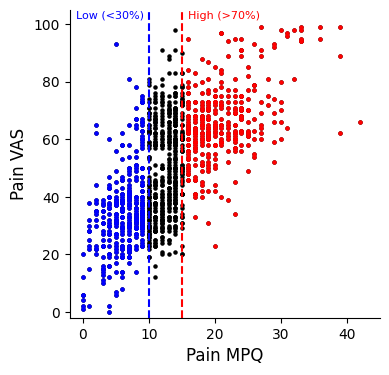

In [5]:
# =============================================================================
# FIGURE 4a – MPQ vs VAS RELATIONSHIP
# =============================================================================
# plot scatter VAS vs MPQ scores to demonstrate inter-metric consistency
# further, show high and low pain surveys using red and blue, respectively
fig, ax = plt.subplots(1, 1, figsize=(4, 4))

# MPQ-VAS correlation across all paired surveys (quoted in the Figure 4a legend)
r_mpq_vas, p_mpq_vas = stats.pearsonr(MPQ_all, VAS_all)
print(f'Figure 4a: Pearson r = {r_mpq_vas:.2f}, two-sided p = {p_mpq_vas:.1e}, n = {len(MPQ_all)} surveys')

# Scatter plots
ax.scatter(MPQ_all, VAS_all, s=5, color="k")
ax.scatter(MPQ_all[i_high_all], VAS_all[i_high_all], s=5, color="r")
ax.scatter(MPQ_all[i_low_all], VAS_all[i_low_all], s=5, color="b")

# Plot vertical lines indicating high and low pain thresholds
ax.axvline(high_pain_threshold, linestyle="--", color="r")
ax.axvline(low_pain_threshold, linestyle="--", color="b")

# labels threshold lines
ax.text(low_pain_threshold - 11, 102, 'Low (<30%)', color='b',fontsize=8)
ax.text(high_pain_threshold + 1, 102, 'High (>70%)', color='r',fontsize=8)

# Set labels and limits
ax.set_ylabel("Pain VAS", fontsize=12)
ax.set_xlabel("Pain MPQ", fontsize=12)
ax.set_xlim(-2, 45)
ax.set_ylim(-2, 105)

# Remove the top x-axis line and right y-axis line
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.savefig(Path(main_dir) / 'figures'/ 'Figure4a.pdf', dpi=300, bbox_inches='tight')
plt.show()

In [6]:
# =============================================================================
# 3. PEAK BAND EXTRACTION & STATISTICS
# =============================================================================
"""
Identify the peak frequency from PSD statistics, compute the band-averaged PSD for that peak,
and run a t-test comparing high vs low pain.

Inputs:
    neural_spectra : DataFrame (surveys x frequencies)
    i_low          : boolean array selecting low pain trials
    i_high         : boolean array selecting high pain trials
    AUC            : array of AUC values per frequency

Outputs:
    first_band         : array of mean PSD values at the first peak band (all trials)
    first_peak_freq    : frequency (Hz) of first peak
    FirstPeakPValue    : t-test result comparing high vs low pain (scipy.stats.Ttest_indResult)
"""
first_band, first_peak_freq, _ = SPU.compute_first_peak_band(neural_spectra, AUC, i_low, i_high)
# Significance of the decoding AUC at the peak band: 1000 permutations of the pain scores
peak_auc, peak_auc_p = SPU.auc_permutation_test(neural_spectra, MPQ, first_peak_freq)

High vs low pain freq band: 7.5 Hz; Ttest_indResult(statistic=8.569805677995758, pvalue=6.25867745958187e-17)


AUC at 7.5 Hz: 0.634; permutation p = 0.0010 (1000 permutations)


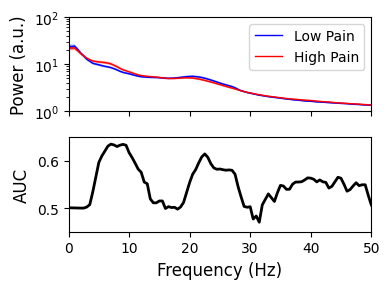

In [7]:
# =============================================================================
# FIGURE 4b –  High vs low pain spectra & AUC decoding across frequencies
# =============================================================================
# Create a 2-row subplot (shared x-axis) 
fig, ax       = plt.subplots(2, 1, figsize=(4, 3), sharex=True)
FigureLegends = []
# Convert to numpy for SPU functions
spectra_vals = neural_spectra.values   # shape: (surveys x frequency)
# prepare frequency values ---
freq_vals = np.array(neural_spectra.columns.astype(float))

# Top subplot: high vs low pain spectra
# Low pain PSD (mean ± 2*SEM) 
GU.shadedErrorBar(
    freq_vals,
    np.mean(spectra_vals[i_low, :], axis=0),                 
    SPU.stderr(spectra_vals[i_low, :], axis=0) * 2,        
    lineprops={"linewidth": 1, "color": "b"},
    alpha=0.3,
    ax=ax[0]
)
FigureLegends.append("Low Pain")
# High pain PSD (mean ± 2*SEM) 
GU.shadedErrorBar(
    freq_vals,
    np.mean(spectra_vals[i_high, :], axis=0),
    SPU.stderr(spectra_vals[i_high, :], axis=0) * 2,
    lineprops={"linewidth": 1, "color": "r"},
    alpha=0.3,
    ax=ax[0])
FigureLegends.append("High Pain")
# Formatting (PSD plot) 
ax[0].set_yscale("log")
ax[0].set_ylim(1, 100)
ax[0].set_xlim(0, 50)
ax[0].legend(ax[0].get_lines(), FigureLegends)
ax[0].set_ylabel("Power (a.u.)", fontsize=12)

# Bottom subplot: AUC curve
ax[1].plot(
    freq_vals[:200],
    SPU.smooth(AUC[:200], 3),
    "k",
    linewidth=2)
# Formatting (AUC plot) 
ax[1].set_xlim(0, 50)
ax[1].set_ylim(0.45, 0.65)
ax[1].set_xlabel("Frequency (Hz)", fontsize=12)
ax[1].set_ylabel("AUC", fontsize=12)
# Render and save figure 
plt.tight_layout()
plt.savefig(Path(main_dir) / 'figures' / 'Figure4b.pdf', dpi=300, bbox_inches='tight')
plt.show()

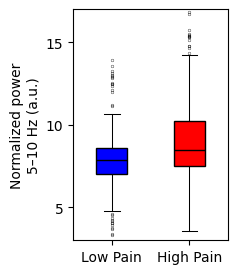

In [8]:
# =============================================================================
# FIGURE 4c – BAND POWER COMPARISON
# =============================================================================
# Boxplot comparison (LOW vs HIGH pain for first peak) 
fig, ax = plt.subplots(1, 1, figsize=(2, 3))

box1 = GU.standardErrorBox(0,  first_band[i_low], color="b", ax=ax)
box2 = GU.standardErrorBox(1,  first_band[i_high], color="r", ax=ax)

ax.set_ylabel(f'Normalized power\n{first_peak_freq - 2.5:g}–{first_peak_freq + 2.5:g} Hz (a.u.)')
ax.set_xticklabels(["Low Pain", "High Pain"])
ax.set_ylim(3, 17)
ax.set_yticks([5,10,15])
plt.savefig(Path(main_dir) / 'figures'/ 'Figure4c.pdf', dpi=300, bbox_inches='tight')
plt.show()